# Comparative Evaluation of Regression Models Using a Diabetes Dataset

A reproducible comparison of Linear Regression, Random Forest, and XGBoost using five baseline predictors and the scikit-learn diabetes progression outcome. The analysis is a methodological demonstration, not a clinical prediction tool.

# Phase 1: Model Exploration

### Import Libraries And Load The Dataset

In [3]:
# Import libraries for data manipulation and analysis
import pandas as pd
import numpy as np

# Import the diabetes dataset from scikit-learn
from sklearn.datasets import load_diabetes

# Load the dataset in pandas format
diabetes = load_diabetes(as_frame=True)

# Create a working copy of the complete dataset
df = diabetes.frame.copy()

# Display the first five observations
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Examine The Dataset Structure

In [4]:
# Identify the number of observations and variables
print("Dataset dimensions:", df.shape)

# Identify available variables
print("\nVariable names:")
print(df.columns.tolist())

# Examine data types and non-missing counts
print("\nDataset information:")
df.info()

Dataset dimensions: (442, 11)

Variable names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


### Selection Of Analytical Variables

In [5]:
# Define the five predictors selected for analysis
predictors = ['age', 'sex', 'bmi', 'bp', 's6']

# Define the outcome variable
outcome = 'target'

# Create a separate analytical dataset
df_model = df[predictors + [outcome]].copy()

# Verify the dimensions
print("Analytical dataset dimensions:", df_model.shape)

# Verify the selected variables
print("\nSelected variables:")
print(df_model.columns.tolist())

# Display the first five observations
display(df_model.head())

Analytical dataset dimensions: (442, 6)

Selected variables:
['age', 'sex', 'bmi', 'bp', 's6', 'target']


,age,sex,bmi,bp,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,-0.046641,135.0


### Check For Duplicates

In [6]:
# Identify exact duplicate rows in the analytical dataset
duplicate_count = df_model.duplicated().sum()

# Display the number of duplicate observations
print("Duplicate observations:", duplicate_count)

Duplicate observations: 0


### General Descriptive Statistics

In [7]:
# Generate descriptive statistics for the analytical dataset
descriptive_stats = df_model.describe().T

# Display statistics rounded to four decimal places
display(descriptive_stats.round(4))

,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.0000,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107
sex,442.0,0.0000,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507
bmi,442.0,-0.0000,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706
bp,442.0,-0.0000,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320
s6,442.0,0.0000,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356
target,442.0,152.1335,77.0930,25.0000,87.0000,140.5000,211.5000,346.0000


### Correlation Analysis

In [8]:
# Calculate Pearson correlations for the analytical dataset
correlation_matrix = df_model.corr(method='pearson')

# Display the correlation matrix
display(correlation_matrix.round(3))

,age,sex,bmi,bp,s6,target
age,1.000,0.174,0.185,0.335,0.302,0.188
sex,0.174,1.000,0.088,0.241,0.208,0.043
bmi,0.185,0.088,1.000,0.395,0.389,0.586
bp,0.335,0.241,0.395,1.000,0.390,0.441
s6,0.302,0.208,0.389,0.390,1.000,0.382
target,0.188,0.043,0.586,0.441,0.382,1.000


### Calculate Variance Inflation Factor (Vif)

In [9]:
# Import variance inflation factor function
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Select predictor variables only
X = df_model[['age', 'sex', 'bmi', 'bp', 's6']]

# Add an intercept for the VIF calculation
X_vif = sm.add_constant(X, has_constant='add')

# Calculate VIF for each predictor, excluding the intercept
vif_results = pd.DataFrame({
    'Variable': X.columns,
    'VIF': [
        variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])
    ]
})

# Display results
display(vif_results.round(3))

,Variable,VIF
0,age,1.180
1,sex,1.088
2,bmi,1.287
3,bp,1.398
4,s6,1.344


### Visualize Variable Distributions

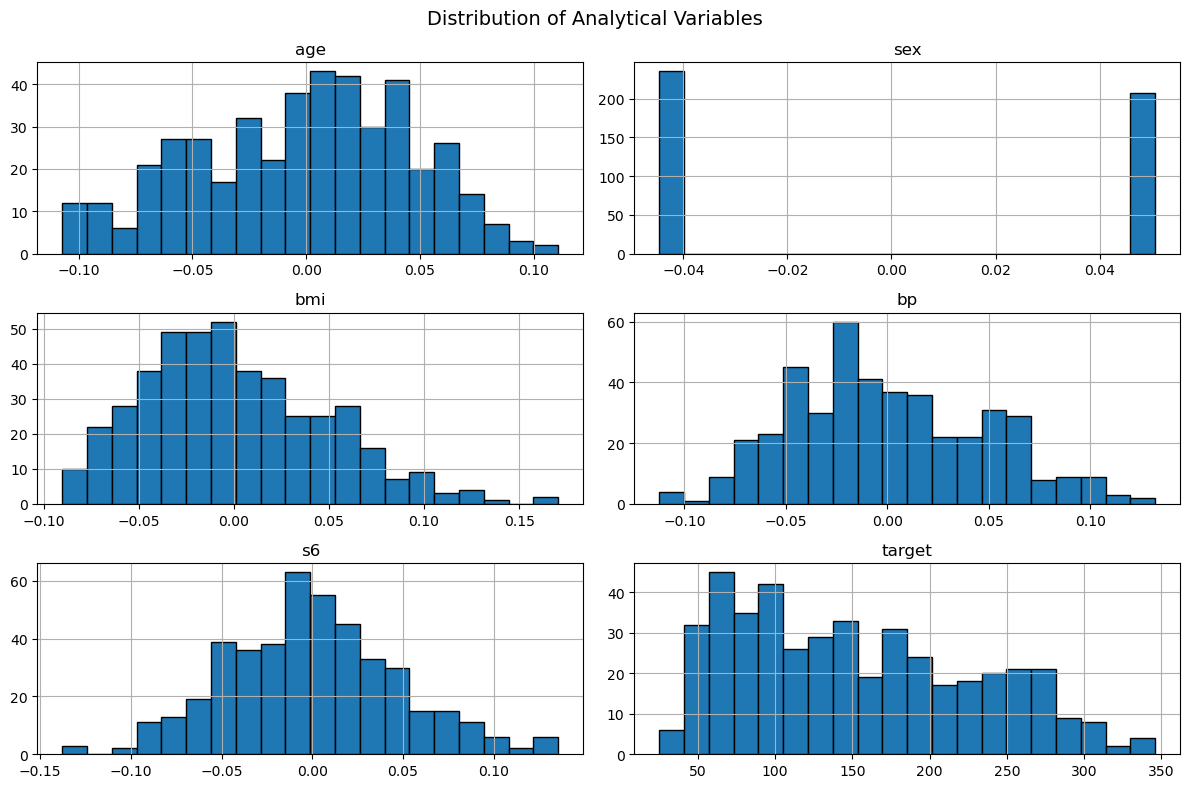

In [10]:
import matplotlib.pyplot as plt

# Create a histogram for each variable
df_model.hist(
    bins=20,
    figsize=(12, 8),
    edgecolor='black'
)

# Add a title and adjust spacing
plt.suptitle("Distribution of Analytical Variables", fontsize=14)
plt.tight_layout()
plt.show()

### Outlier Assessment

In [11]:
# Select continuous predictors and the outcome
continuous_vars = ['age', 'bmi', 'bp', 's6', 'target']

# Store outlier assessment results
outlier_results = []

# Evaluate each variable using the IQR method
for variable in continuous_vars:
    Q1 = df_model[variable].quantile(0.25)
    Q3 = df_model[variable].quantile(0.75)

    IQR = Q3 - Q1

    # Calculate lower and upper outlier boundaries
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    # Count observations outside the boundaries
    outlier_count = (
        (df_model[variable] < lower_bound) |
        (df_model[variable] > upper_bound)
    ).sum()

    outlier_results.append({
        'Variable': variable,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': outlier_count
    })

# Create a summary table
outlier_summary = pd.DataFrame(outlier_results)

# Display results
display(outlier_summary.round(4))

,Variable,Lower_Bound,Upper_Bound,Outlier_Count
0,age,-0.1504,0.1511,0
1,bmi,-0.1324,0.1295,3
2,bp,-0.1451,0.1441,0
3,s6,-0.1248,0.1196,9
4,target,-99.7500,398.2500,0


# Phase 2: Data Preparation

### Define The Predictors And Outcome

In [13]:
# Import the function for splitting the dataset
from sklearn.model_selection import train_test_split

# Define the five predictor variables
X = df_model[['age', 'sex', 'bmi', 'bp', 's6']]

# Define the continuous outcome variable
y = df_model['target']

# Confirm the dimensions
print("Predictor dataset:", X.shape)
print("Outcome dataset:", y.shape)

Predictor dataset: (442, 5)
Outcome dataset: (442,)


### Create Training And Testing Subsets

In [14]:
# Split the data into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display the number of observations in each subset
print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

# Confirm the number of predictor variables
print("\nTraining predictors:", X_train.shape[1])
print("Testing predictors:", X_test.shape[1])

Training observations: 353
Testing observations: 89

Training predictors: 5
Testing predictors: 5


# Phase 3: Linear Regression — Baseline Model

### Train The Baseline Model

In [16]:
# Import Linear Regression from scikit-learn
from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
linear_model = LinearRegression()

# Fit the model using the training data
linear_model.fit(X_train, y_train)

# Generate predictions using the held-out test data
y_pred_linear = linear_model.predict(X_test)

# Confirm that the model was trained
print("Linear Regression model trained successfully.")
print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))
print("Predictions generated:", len(y_pred_linear))

Linear Regression model trained successfully.
Training observations: 353
Testing observations: 89
Predictions generated: 89


### Linear Regression Model Perfomance Evaluation

In [17]:
# Import regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate Mean Absolute Error
linear_mae = mean_absolute_error(y_test, y_pred_linear)

# Calculate Root Mean Squared Error
linear_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

# Calculate R-squared
linear_r2 = r2_score(y_test, y_pred_linear)

# Display model performance results
print("Linear Regression Model Performance")
print("-----------------------------------")
print(f"MAE:  {linear_mae:.3f}")
print(f"RMSE: {linear_rmse:.3f}")
print(f"R²:   {linear_r2:.3f}")

Linear Regression Model Performance
-----------------------------------
MAE:  49.893
RMSE: 60.074
R²:   0.319


### Examine Regression Coefficients

In [18]:
# Create a table of predictor coefficients
linear_coefficients = pd.DataFrame({
    'Predictor': X_train.columns,
    'Coefficient': linear_model.coef_
})

# Display coefficients and model intercept
print("Linear Regression Intercept:")
print(round(linear_model.intercept_, 3))

print("\nRegression Coefficients:")
display(linear_coefficients.round(3))

Linear Regression Intercept:
151.576

Regression Coefficients:


,Predictor,Coefficient
0,age,29.946
1,sex,-118.463
2,bmi,768.926
3,bp,356.535
4,s6,203.064


### Residual Analysis

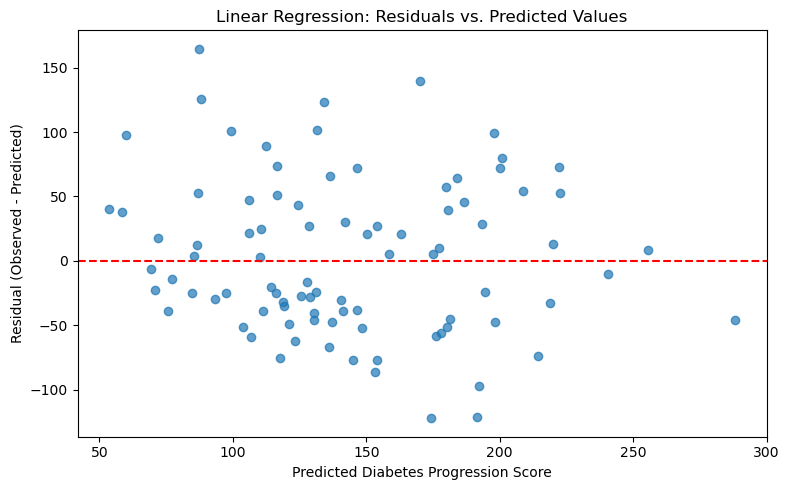

In [19]:
# Import plotting library
import matplotlib.pyplot as plt

# Calculate residuals for the testing dataset
linear_residuals = y_test - y_pred_linear

# Plot residuals against predicted values
plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_linear,
    linear_residuals,
    alpha=0.7
)

# Add a reference line at zero
plt.axhline(y=0, color='red', linestyle='--')

# Add labels and title
plt.xlabel("Predicted Diabetes Progression Score")
plt.ylabel("Residual (Observed - Predicted)")
plt.title("Linear Regression: Residuals vs. Predicted Values")

plt.tight_layout()
plt.show()

# Phase 4: Random Forest Regression

### Train The Random Forest Model

In [21]:
# Import Random Forest Regression
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model using the training dataset
random_forest_model.fit(X_train, y_train)

# Generate predictions using the testing dataset
y_pred_rf = random_forest_model.predict(X_test)

# Confirm model training and prediction generation
print("Random Forest model trained successfully.")
print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))
print("Predictions generated:", len(y_pred_rf))

Random Forest model trained successfully.
Training observations: 353
Testing observations: 89
Predictions generated: 89


### Random Forest Model Performance Evaluation

In [22]:
# Calculate Mean Absolute Error
rf_mae = mean_absolute_error(y_test, y_pred_rf)

# Calculate Root Mean Squared Error
rf_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

# Calculate R-squared
rf_r2 = r2_score(y_test, y_pred_rf)

# Display Random Forest evaluation results
print("Random Forest Model Performance")
print("--------------------------------")
print(f"MAE:  {rf_mae:.3f}")
print(f"RMSE: {rf_rmse:.3f}")
print(f"R²:   {rf_r2:.3f}")

Random Forest Model Performance
--------------------------------
MAE:  48.606
RMSE: 62.789
R²:   0.256


### Random Forest Feature Importance

In [23]:
# Extract feature importance from the trained Random Forest model
rf_importance = pd.DataFrame({
    'Predictor': X_train.columns,
    'Importance': random_forest_model.feature_importances_
})

# Sort predictors from highest to lowest importance
rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance
print("Random Forest Feature Importance:")
display(rf_importance.round(4))

Random Forest Feature Importance:


,Predictor,Importance
2,bmi,0.5098
3,bp,0.1864
4,s6,0.1559
0,age,0.1267
1,sex,0.0212


### Random Forest Residual Analysis

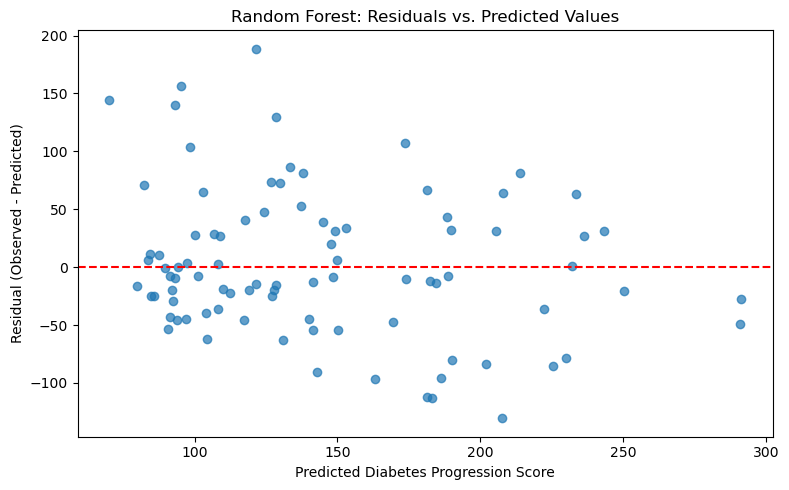

In [24]:
# Calculate Random Forest residuals
rf_residuals = y_test - y_pred_rf

# Plot residuals against predicted values
plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_rf,
    rf_residuals,
    alpha=0.7
)

# Add a horizontal reference line at zero
plt.axhline(y=0, color='red', linestyle='--')

# Add labels and title
plt.xlabel("Predicted Diabetes Progression Score")
plt.ylabel("Residual (Observed - Predicted)")
plt.title("Random Forest: Residuals vs. Predicted Values")

plt.tight_layout()
plt.show()

# Phase 5: XGBoost Regression

### Train The Xgboost Model

In [26]:
# Import the XGBoost regression model
from xgboost import XGBRegressor

# Initialize the XGBoost model
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=1
)

# Train the model using the training dataset
xgb_model.fit(X_train, y_train)

# Generate predictions using the testing dataset
y_pred_xgb = xgb_model.predict(X_test)

# Confirm model training and predictions
print("XGBoost model trained successfully.")
print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))
print("Predictions generated:", len(y_pred_xgb))

XGBoost model trained successfully.
Training observations: 353
Testing observations: 89
Predictions generated: 89


### Xg Boost Model Perfomance Evaluation

In [27]:
# Calculate Mean Absolute Error
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

# Calculate Root Mean Squared Error
xgb_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

# Calculate R-squared
xgb_r2 = r2_score(y_test, y_pred_xgb)

# Display XGBoost model performance
print("XGBoost Model Performance")
print("-------------------------")
print(f"MAE:  {xgb_mae:.3f}")
print(f"RMSE: {xgb_rmse:.3f}")
print(f"R²:   {xgb_r2:.3f}")

XGBoost Model Performance
-------------------------
MAE:  48.886
RMSE: 60.241
R²:   0.315


### Xgboost Feature Importance

In [28]:
# Extract feature importance from the fitted XGBoost model
xgb_importance = pd.DataFrame({
    'Predictor': X_train.columns,
    'Importance': xgb_model.feature_importances_
})

# Sort predictors from highest to lowest importance
xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance results
print("XGBoost Feature Importance:")
display(xgb_importance.round(4))

XGBoost Feature Importance:


,Predictor,Importance
2,bmi,0.5385
3,bp,0.1979
4,s6,0.1392
0,age,0.0704
1,sex,0.0540


### Xgboost Residual Analysis

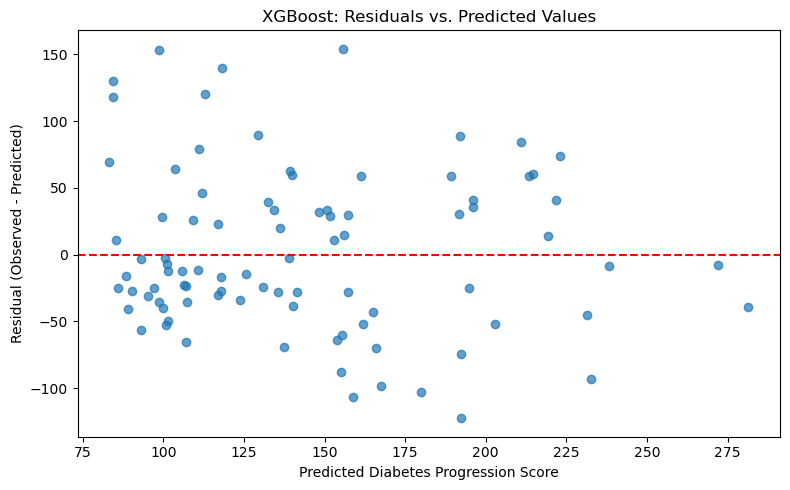

In [29]:
# Calculate residuals for the XGBoost model
xgb_residuals = y_test - y_pred_xgb

# Plot residuals against predicted values
plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_xgb,
    xgb_residuals,
    alpha=0.7
)

# Add a reference line at zero
plt.axhline(y=0, color='red', linestyle='--')

# Label the plot
plt.xlabel("Predicted Diabetes Progression Score")
plt.ylabel("Residual (Observed - Predicted)")
plt.title("XGBoost: Residuals vs. Predicted Values")

plt.tight_layout()
plt.show()

# Phase 6: Model Comparison and Interpretation

In [31]:

# Create a table containing performance metrics
# from the three regression models

model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'XGBoost'
    ],
    'MAE': [
        linear_mae,
        rf_mae,
        xgb_mae
    ],
    'RMSE': [
        linear_rmse,
        rf_rmse,
        xgb_rmse
    ],
    'R2': [
        linear_r2,
        rf_r2,
        xgb_r2
    ]
})

# Display the model comparison table
display(model_comparison.round(3))


,Model,MAE,RMSE,R2
0,Linear Regression,49.893,60.074,0.319
1,Random Forest,48.606,62.789,0.256
2,XGBoost,48.886,60.241,0.315


### Visualize Model Performance

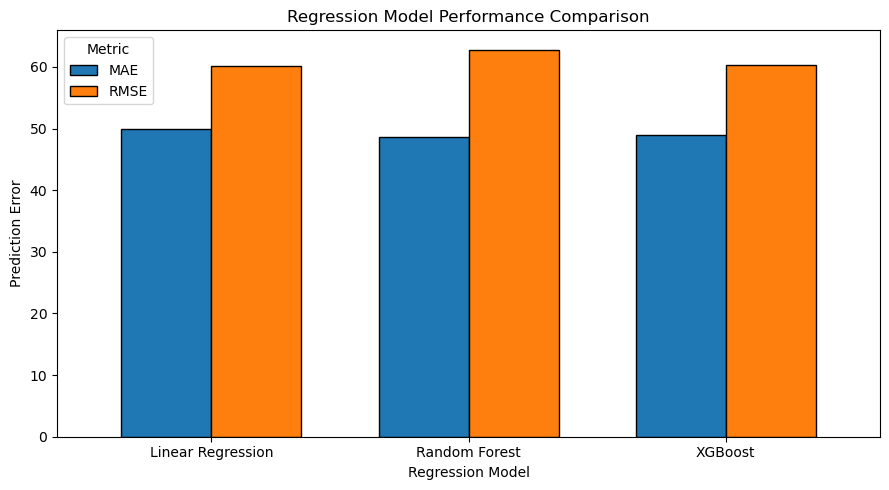

In [32]:
# Prepare the performance data for visualization
metrics_to_plot = model_comparison.set_index('Model')[
    ['MAE', 'RMSE']
]

# Create a grouped bar chart
ax = metrics_to_plot.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.7,
    edgecolor='black'
)

# Add titles and axis labels
plt.title("Regression Model Performance Comparison")
plt.xlabel("Regression Model")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.legend(title="Metric")

# Improve layout
plt.tight_layout()
plt.show()